# Step 4 - From a model alone to a complete RAG

We start with a language model and nothing else, and we add one piece at a time:

1. the model alone, on a general question;
2. the model alone, on a question about our documents;
3. the model with the right text pasted by hand;
4. the text found automatically: **retrieve**, with the hybrid search and the re-ranker of step 3;
5. the text placed in the prompt with its source: **augment**;
6. the answer written from that text: **generate**.

At the end the three steps fit in one function, the complete RAG, and we check on the golden set
what the re-ranker adds.

Before running: put your key in `.env` (see `.env.example`), parse the corpus with
`python -m src.ingestion.parsing` and start the vector database with `docker compose up -d`.

In [1]:
import os
import warnings

# Keep the output clean: no progress bars and no notices while the models load.
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import textwrap
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from src.config import load_config, load_env_file, project_path, require_env
from src.evaluation import load_golden_set, retrieval_result
from src.ingestion.chunking import chunk_document, load_tokenizer
from src.ingestion.parsing import load_corpus
from src.llm import ChatClient, Reply
from src.rag import passage_text
from src.retrieval.embedding import BgeM3Embedder
from src.retrieval.reranking import CrossEncoderReranker
from src.retrieval.vector_store import Hit, QdrantStore

config = load_config()
load_env_file(project_path(config.paths.env_file))
llm = ChatClient(config.llm, require_env(config.llm.api_key_env))


def show(reply: Reply) -> None:
    """Print an answer of the model, wrapped, with the name of the model that wrote it."""
    for paragraph in reply.text.splitlines():
        print(textwrap.fill(paragraph, width=100))
    print(f"\n[{reply.model}]")


print("model:", config.llm.model)

model: nvidia/nemotron-3-ultra-550b-a55b:free


## 1. The model alone, a general question

One call: a question goes in, text comes out.

In [3]:
show(llm.ask("In due frasi: che cos'è il recesso da un contratto?"))

Il recesso è l'atto unilaterale con cui una parte dichiara di voler sciogliere il vincolo
contrattuale, facendolo venire meno con effetto per il futuro (ex nunc). Può essere esercitato per
volontà della legge (recesso legale) o per previsione delle parti nel contratto (recesso
convenzionale), spesso nel rispetto di un termine di preavviso.

[nvidia/nemotron-3-ultra-550b-a55b:free]


This is general knowledge: the model has read plenty of it during training.

The name in brackets says which model wrote the answer. Free models are shared and sometimes busy:
the client tries again a few times before giving up, so an answer can take a minute.

## 2. The model alone, a question about us

Now something that only our documents know.

In [4]:
QUESTION = "Con quanto preavviso possiamo recedere dal contratto CTR-2024-017 con Beta Idroservizi?"

show(llm.ask(QUESTION))

Non ho accesso al testo del contratto **CTR-2024-017** né a database privati o documenti legali
specifici tra la tua azienda e **Beta Idroservizi**.

Per conoscere il preavviso esatto devi fare riferimento a:

1.  **Il testo del contratto**: Cerca la clausola relativa a **"Risoluzione", "Recesso", "Durata" o
"Termine del contratto"**. Spesso è indicato in giorni (es. 30, 60, 90, 180 giorni) o legato a
scadenze annuali.
2.  **Eventuali Allegati o Ordini di Acquisto**: A volte le condizioni di recesso sono negli
allegati tecnici o economici.
3.  **Corrispondenza ufficiale**: Verifica se ci sono state integrazioni o modifiche successive
(addendum) inviate via PEC o raccomandata.
4.  **Il tuo Ufficio Legale / Amministrativo**: Chi gestisce i contratti in azienda dovrebbe avere
una copia firmata o un riepilogo delle scadenze chiave (contract management).

**Attenzione:** Verifica anche *come* deve essere comunicato il recesso (solitamente **PEC** o
**Raccomandata A/R**) per far decorrere co

The model says it plainly: it has no access to our contracts, and all it can offer is generic advice.
Another model, or another run, may produce a plausible number instead, which is worse.
Training does not help here: **the model needs the text**.

## 3. We paste the text by hand

We know where to look: Art. 7 of the contract is about withdrawal. We put it in the prompt, above the question.

In [5]:
documents = load_corpus(project_path(config.paths.parsed_dir))
tokenizer = load_tokenizer(config.embedding.model_name)
chunks = [chunk for document in documents for chunk in chunk_document(document, tokenizer, config.chunking)]

contract = [chunk for chunk in chunks if "01_contratti/CTR-2024-017" in chunk.source]
article_7 = next(chunk for chunk in contract if chunk.section.startswith("Art. 7"))
prompt = f"Use this text to answer.\n\n{article_7.text}\n\nQuestion: {QUESTION}"
print(prompt)

Use this text to answer.

## Art. 7 - Recesso

Il Committente può recedere dal contratto in qualsiasi momento, con preavviso di 60 (sessanta) giorni.

In caso di recesso il Committente riconosce al Fornitore, oltre al pagamento delle prestazioni eseguite, un indennizzo pari a 2 (due) mensilità del corrispettivo.

Il Fornitore può recedere dal contratto esclusivamente per giusta causa, con preavviso di 180 (centottanta) giorni, garantendo in ogni caso la continuità delle prestazioni fino al subentro di un nuovo operatore.

Question: Con quanto preavviso possiamo recedere dal contratto CTR-2024-017 con Beta Idroservizi?


In [6]:
show(llm.ask(prompt))

In base **esclusivamente al testo dell'Art. 7 fornito**, la risposta dipende da quale parte sei tu
nel contratto (Committente o Fornitore), poiché il testo non specifica chi sia "Beta Idroservizi" né
chi sia il soggetto che pone la domanda ("noi").

Ecco le due possibilità previste dall'articolo:

1.  **Se "noi" siamo il Committente (il cliente che commissiona il servizio):**
    Puoi recedere **in qualsiasi momento**, con un preavviso di **60 (sessanta) giorni**.

2.  **Se "noi" siamo il Fornitore (Beta Idroservizi, chi esegue le prestazioni):**
    Puoi recedere **esclusivamente per giusta causa**, con un preavviso di **180 (centottanta)
giorni**, garantendo la continuità delle prestazioni fino al subentro di un nuovo operatore.

*Nota: Il testo prevede inoltre che, in caso di recesso del Committente, questi debba corrispondere
al Fornitore un indennizzo pari a 2 mensilità del corrispettivo, oltre al pagamento delle
prestazioni già eseguite.*

[nvidia/nemotron-3-ultra-550b-a55b:free]

Same model, same question: now the answer comes from our contract, **60 days** for the customer.
This is the whole idea of RAG: **the model answers from text that we put in the prompt.**

Look at how the answer begins: the article alone does not say which party we are.
A passage taken out of its document loses part of its meaning.

Two things are still wrong. We had to know in advance where the answer was, and the corpus has 1754 chunks.
And we trusted one article: is it the whole story? Keep those 60 days in mind.

## 4. Retrieve: we find the text automatically

Step 3 gave us the tools. The chunks are in the vector database, each with its dense and its sparse
vector. A hybrid search returns the candidates, the re-ranker reads each of them together with the
question, and the best ones are kept.

In [7]:
embedder = BgeM3Embedder(config.embedding)
reranker = CrossEncoderReranker(config.reranking)
store = QdrantStore.connect(config.vector_store, config.retrieval)
TOP_K, CANDIDATES = config.reranking.top_k, config.retrieval.candidates

print(f"{store.count()} chunks in the vector database, {config.retrieval.mode} search")
print(f"{CANDIDATES} candidates go to the re-ranker, {TOP_K} chunks reach the prompt")

1754 chunks in the vector database, hybrid search
50 candidates go to the re-ranker, 10 chunks reach the prompt


In [8]:
def retrieve(question: str, rerank: bool = True) -> list[Hit]:
    """The best chunks for a question: the search alone, or the search followed by the re-ranker."""
    embedded = embedder.embed([question])
    if not rerank:
        return store.search(embedded.dense[0], embedded.sparse[0], TOP_K)
    candidates = store.search(embedded.dense[0], embedded.sparse[0], CANDIDATES)
    scores = reranker.score(question, [passage_text(hit) for hit in candidates])
    best = np.argsort(scores)[::-1][:TOP_K]
    return [Hit(candidates[index].chunk, scores[index]) for index in best]


def show_hits(hits: list[Hit]) -> None:
    """Print one line per retrieved chunk: position, score, document and section."""
    for position, hit in enumerate(hits, start=1):
        document = Path(hit.chunk.source).name[:44]
        print(f"{position:2d}  {hit.score:.3f}  {document:44s}  {hit.chunk.section[:36]}")


hits = retrieve(QUESTION)
show_hits(hits)

 1  0.999  VRB-2025-02_comitato-manutenzione_2025-01-30  2. Condizioni di recesso del contrat
 2  0.999  EML-2025-04_chiarimento-preavviso-recesso-be  
 3  0.999  EML-2025-01_proposta-addendum-recesso-beta.t  
 4  0.998  CTR-2024-017_addendum-01_Beta.pdf             Art. 1 - Modifica dell'Art. 7 (Reces
 5  0.997  EML-2025-01_proposta-addendum-recesso-beta.t  
 6  0.996  VRB-2025-02_comitato-manutenzione_2025-01-30  Decisioni
 7  0.990  CTR-2024-025_Omicron_trasporti-e-movimentazi  Art. 7 - Recesso
 8  0.990  CTR-2025-030_Beta_pronto-intervento-e-nolegg  Art. 7 - Recesso
 9  0.989  CTR-2024-005_Ypsilon_licenze-e-manutenzione-  Art. 7 - Recesso
10  0.988  CTR-2024-019_Gamma_manutenzione-pompe-centri  Art. 7 - Recesso


Look at what came back. The article we pasted by hand is not in the list. At the top there are the
minutes of a committee, two e-mail threads and an addendum: all of them talk about the withdrawal
from this contract. The retriever found documents that we did not know we had to read.

The score is the one of the re-ranker: how well a chunk answers the question, between 0 and 1.
The last four chunks are Art. 7 of other contracts. They look alike, and it will be up to the model
to leave them aside.

One of the chunks at the top, an e-mail of December 2025:

In [9]:
print(next(hit.chunk.text for hit in hits if "EML-2025-04" in hit.chunk.source))

Da: Marta Colombini <marta.colombini@torrevalleacque.example>
A: Luca Bassi <luca.bassi@torrevalleacque.example>
Cc: Dario Ferrante <dario.ferrante@torrevalleacque.example>
Inviato: 09/12/2025 17:40
Oggetto: R: Preavviso recesso contratto Beta

Ciao Luca,

no, attenzione. Con Beta abbiamo tre contratti e i preavvisi sono diversi.

Per il contratto di manutenzione delle pompe sommergibili, CTR-2024-017, il preavviso di recesso è di 45 giorni dal 1° marzo 2025, per effetto dell'addendum n. 1; nel testo originale del contratto era di 60 giorni.

I 30 giorni che ricordi sono quelli del contratto di pronto intervento e noleggio, CTR-2025-030. Per il contratto di fornitura delle pompe, CTR-2023-009, il preavviso è di 90 giorni.

In ogni caso il recesso si comunica solo a mezzo PEC e lo invia il mio ufficio.

Marta


The notice was changed: **45 days, not 60**, since 1 March 2025, by Addendum 1.

In section 3 we pasted the original article and got an answer that was right in 2024 and is wrong today.
One article was not the whole story.

## 5. Augment: the passages go into the prompt, with their source

The prompt has three parts: instructions that do not change, the retrieved passages, the question.
Every passage carries the name of its document, so that the model can say where a fact comes from.

In [10]:
SYSTEM = (
    "You answer questions about the documents of the company Torrevalle Acque. "
    "Use only the passages in the prompt and name the document each fact comes from. "
    "When passages disagree, explain which one applies today and why. "
    "If the passages do not contain the answer, say that you do not know. "
    f"Today is {date.today():%d %B %Y}. Answer in the language of the question."
)


def build_prompt(question: str, hits: list[Hit]) -> str:
    """The prompt of the model: the retrieved passages, numbered and with their source, then the question."""
    passages = [
        f"[{number}] {Path(hit.chunk.source).name} | {hit.chunk.section}\n{hit.chunk.text}"
        for number, hit in enumerate(hits, start=1)
    ]
    return "Passages:\n\n" + "\n\n".join(passages) + f"\n\nQuestion: {question}"


prompt = build_prompt(QUESTION, hits)
print(prompt[:900], "\n[...]\n", prompt[-90:])

Passages:

[1] VRB-2025-02_comitato-manutenzione_2025-01-30.md | 2. Condizioni di recesso del contratto di manutenzione delle pompe sommergibili
## 2. Condizioni di recesso del contratto di manutenzione delle pompe sommergibili

Colombini illustra la proposta di ridurre il preavviso di recesso del contratto CTR-2024-017 con Beta Idroservizi, oggi pari a 60 giorni. Il fornitore ha dato disponibilità a scendere a 45 giorni.

Viene valutata anche l'ipotesi di un preavviso di 30 giorni, che il fornitore non ha accettato: l'ipotesi è scartata.

Il comitato approva la riduzione a 45 giorni. Resta invariato il termine di 90 giorni per la disdetta alla scadenza.

[2] EML-2025-04_chiarimento-preavviso-recesso-beta.txt | 
Da: Marta Colombini <marta.colombini@torrevalleacque.example>
A: Luca Bassi <luca.bassi@torrevalleacque.example>
Cc: Dario Ferrante <dario.ferrante@torrevalleacque.example>
Invia 
[...]
 n: Con quanto preavviso possiamo recedere dal contratto CTR-2024-017 con Beta Idroservizi?


## 6. Generate: the model answers from the passages

In [11]:
show(llm.ask(prompt, system=SYSTEM))

Il preavviso di recesso per il contratto **CTR-2024-017** (manutenzione pompe sommergibili con Beta
Idroservizi) è di **45 giorni**.

**Fonti:**
- L’addendum n. 1 al contratto, firmato con effetto dal 1° marzo 2025, sostituisce l’art. 7
stabilendo: «Il Committente può recedere dal contratto in qualsiasi momento, con preavviso di 45
(quarantacinque) giorni»【4】.
- Il comitato manutenzione ha approvato la riduzione da 60 a 45 giorni (scartando l’ipotesi di 30
giorni)【1】【6】.
- Una successiva email di conferma precisa che, per effetto dell’addendum, il preavviso è di 45
giorni dal 1° marzo 2025【2】.
- Il fornitore Beta Idroservizi ha confermato la disponibilità a 45 giorni, rifiutando i 30
giorni【3】.

Poiché oggi è il 12 ottobre 2026, l’addendum è pienamente efficace e il preavviso applicabile è **45
giorni**.

[nvidia/nemotron-3-ultra-550b-a55b:free]


**45 days**, in force since 1 March 2025 because of Addendum 1. The answer lists the passages it used:
the e-mails, the minutes of the committee, the addendum. It also explains the other numbers: 60 was the
original text, 30 a proposal that was rejected.

Compare with section 3. There we chose one article and got 60 days, an answer that was right in 2024.
Here the retriever chose, and it found the documents that tell the rest of the story.

## The complete RAG

Retrieve, augment, generate: one function.

In [12]:
def answer(question: str, rerank: bool = True) -> None:
    """Answer a question from the documents and list the passages that were given to the model."""
    hits = retrieve(question, rerank)
    show(llm.ask(build_prompt(question, hits), system=SYSTEM))
    print("\npassages given to the model:")
    show_hits(hits)

A question about a machine:

In [13]:
answer("Cosa significa l'allarme E-4012 sulla pompa P7?")

L'allarme **E-4012** sulla pompa P7 indica **un'infiltrazione d'acqua nella camera olio** (camera
delle tenute).

**Dettagli principali (dai manuali):**

| Aspetto | Descrizione | Fonte |
|---------|-------------|-------|
| **Significato** | Il sensore conduttivo nella camera olio rileva la presenza di acqua. | [1], [6]
|
| **Gravità** | **Allarme** (non blocca la pompa, ma richiede intervento). | [1], [7] |
| **Ripristino** | **Manuale** (non si resetta da solo). | [1], [7] |
| **Cause probabili** | Usura della tenuta meccanica inferiore; cavo o filamenti avvolti
sull'albero; urti sulla girante. | [6] |
| **Tempo massimo di esercizio con allarme attivo** | **24 ore** – la pompa può restare in servizio
al massimo per questo periodo. | [1], [6] |
| **Intervento richiesto entro 24 h** | Sollevare la pompa, controllare l'olio e **sostituire la
tenuta meccanica inferiore** (ricambio **RIC‑P7‑0031**). | [1], [6] |

**Esempi pratici dai ticket:**
In tutti i casi registrati (TK‑2025‑0031, TK‑

A question about a person:

In [14]:
answer("Chi è il legale rappresentante di Beta Idroservizi?")

Il legale rappresentante di **Beta Idroservizi S.r.l.** è **Guido Santoro**.

Questa informazione compare in tutti i contratti e addendum che coinvolgono Beta Idroservizi
presenti nei documenti forniti:
- CTR-2025-030 (passaggio [1])
- CTR-2024-017 (passaggio [2])
- CTR-2023-009 (passaggio [3])
- Addendum n. 1 al CTR-2024-017 (passaggio [4])
- Addendum n. 2 al CTR-2024-017 (passaggio [5])

In ciascuno di questi documenti la società è indicata come «Beta Idroservizi S.r.l., con sede legale
in Viale delle Officine 21, Castelrovo, codice fiscale e partita IVA 00845170992, in persona del
legale rappresentante Guido Santoro».

[nvidia/nemotron-3-ultra-550b-a55b:free]

passages given to the model:
 1  0.998  CTR-2025-030_Beta_pronto-intervento-e-nolegg  e
 2  0.997  CTR-2024-017_Beta_manutenzione-pompe-sommerg  e
 3  0.997  CTR-2023-009_Beta_fornitura-pompe-sommergibi  e
 4  0.993  CTR-2024-017_addendum-01_Beta.pdf             ADDENDUM N. 1 AL CONTRATTO N. CTR-20
 5  0.993  CTR-2024-017_adde

And a question that the documents cannot answer:

In [15]:
answer("Qual è il numero di cellulare del Direttore Generale?")

Non lo so. I documenti forniti menzionano Elena Sartori come Direttore Generale di Torrevalle Acque
S.p.A. in diversi contratti (CTR-2024-022, CTR-2025-014, CTR-2024-005, CTR-2024-017, CTR-2024-019,
CTR-2025-016, CTR-2025-030, CTR-2024-030, CTR-2023-004), ma nessuno di essi riporta il suo numero di
cellulare.

[nvidia/nemotron-3-ultra-550b-a55b:free]

passages given to the model:
 1  0.050  CTR-2024-022_addendum-01_Epsilon.pdf          ADDENDUM N. 1 AL CONTRATTO N. CTR-20
 2  0.044  CTR-2025-014_addendum-01_Delta.pdf            ADDENDUM N. 1 AL CONTRATTO N. CTR-20
 3  0.040  CTR-2024-005_addendum-01_Ypsilon.pdf          ADDENDUM N. 1 AL CONTRATTO N. CTR-20
 4  0.039  CTR-2024-017_addendum-01_Beta.pdf             ADDENDUM N. 1 AL CONTRATTO N. CTR-20
 5  0.037  CTR-2024-019_Gamma_manutenzione-pompe-centri  CONTRATTO DI MANUTENZIONE
 6  0.036  CTR-2025-016_Kappa_analisi-di-laboratorio-ac  CONTRATTO DI SERVIZI
 7  0.036  CTR-2025-030_Beta_pronto-intervento-e-nolegg  CONTRATTO DI SERVIZI
 8

## Validation: what the re-ranker adds

Three questions that went well prove little. The golden set has 15 questions that the documents can
answer, each with the passages that hold the answer. For every question we look at the ten chunks
that reach the prompt, with the search alone and with the re-ranker after it:

- **Recall**: the share of the golden passages that are among the ten;
- **MRR**: how high the first of them is (1 when it is always first);
- **NDCG**: the quality of the whole order;
- **Context recall**: the share of the facts of the correct answer that the ten chunks contain.

No language model is called. The re-ranker reads 50 candidates for each question: on a laptop CPU
this cell takes a couple of minutes.

In [16]:
questions = load_golden_set(project_path(config.paths.golden_set))
golden = [question for question in questions if question.answerable]
METRICS = {
    f"Recall@{TOP_K}": "recall",
    "MRR": "reciprocal_rank",
    f"NDCG@{TOP_K}": "ndcg",
    "Context recall": "context_recall",
}


def measure(rerank: bool) -> dict[str, float]:
    """Retrieval metrics on the golden set, averaged over the questions."""
    rows = [retrieval_result(question, retrieve(question.question, rerank)) for question in golden]
    return {name: float(np.mean([getattr(row, field) for row in rows])) for name, field in METRICS.items()}


without, with_reranker = measure(rerank=False), measure(rerank=True)
print(f"{'':16} {'search only':>12} {'with re-ranker':>15}")
for name in METRICS:
    print(f"{name:16} {without[name]:12.2f} {with_reranker[name]:15.2f}")

                  search only  with re-ranker
Recall@10                0.60            0.86
MRR                      0.59            0.82
NDCG@10                  0.53            0.79
Context recall           0.73            0.87


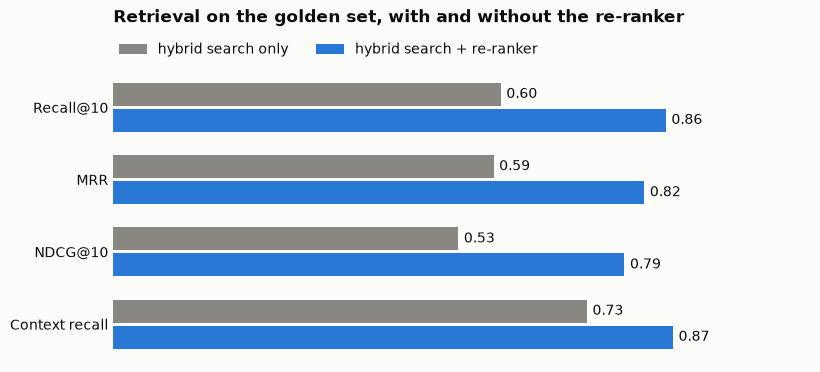

In [17]:
INK, MUTED, SURFACE = "#0b0b0b", "#898781", "#fcfcfb"
BLUE = "#2a78d6"
plt.rcParams.update(
    {"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "font.size": 10}
)

rows = np.arange(len(METRICS))
figure, axis = plt.subplots(figsize=(9, 3.8))
series = (("hybrid search only", without, MUTED), ("hybrid search + re-ranker", with_reranker, BLUE))
for offset, (label, values, color) in enumerate(series):
    heights = rows + (offset - 0.5) * 0.36
    bars = axis.barh(heights, list(values.values()), height=0.32, color=color, label=label)
    axis.bar_label(bars, labels=[f"{value:.2f}" for value in values.values()], padding=4, color=INK)
axis.set_yticks(rows, list(METRICS))
axis.invert_yaxis()
axis.set_xlim(0, 1.08)
axis.set_xticks([])
axis.tick_params(length=0, colors=INK)
axis.spines[:].set_visible(False)
axis.legend(loc="lower left", bbox_to_anchor=(-0.01, 1.0), ncol=2, frameon=False)
title = "Retrieval on the golden set, with and without the re-ranker"
axis.set_title(title, loc="left", fontweight="bold", pad=34)
plt.show()

Every metric goes up with the re-ranker. Recall says that more of the passages that hold the answer
reach the prompt (0.60 to 0.86), MRR that the first of them is almost always at the top (0.59 to
0.82), and Context recall that the facts of the correct answer are in the text the model reads more
often (0.73 to 0.87).

Numbers about retrieval matter only if they change the answer. One question of the golden set,
asked twice: first with the search alone.

In [18]:
CHECK = "Con quanto preavviso può recedere il Committente dal contratto CTR-2023-015?"

answer(CHECK, rerank=False)

Non lo so. I passaggi forniti non contengono le condizioni di recesso del contratto CTR-2023-015. Il
documento [2] (VRB-2026-06_riunione-acquisti_2026-06-18.md) menziona solo che il contratto è stato
rinnovato fino al 31 ottobre 2027, senza specificare il preavviso per il recesso. Gli altri
documenti si riferiscono a contratti diversi (CTR-2024-017, CTR-2025-013, CTR-2025-019,
CTR-2025-028, CTR-2024-005, CTR-2026-006, CTR-2025-022, CTR-2024-013, CTR-2025-016).

[nvidia/nemotron-3-ultra-550b-a55b:free]

passages given to the model:
 1  0.033  CTR-2024-017_addendum-01_Beta.pdf             Art. 1 - Modifica dell'Art. 7 (Reces
 2  0.031  VRB-2026-06_riunione-acquisti_2026-06-18.md   Decisioni
 3  0.028  CTR-2025-013_Omega_rifacimento-vasche-depura  Art. 7 - Recesso
 4  0.028  CTR-2025-019_Theta_lavori-di-carpenteria-e-t  Art. 7 - Recesso
 5  0.028  CTR-2025-028_Ypsilon_sviluppo-portale-ticket  Art. 7 - Recesso
 6  0.027  CTR-2024-005_Ypsilon_licenze-e-manutenzione-  Art. 7 - Recesso
 7  0.

The model is honest: it does not know. Look at the passages it was given: an addendum of
CTR-2024-017, the minutes of a meeting and Art. 7 of eight other contracts. Almost all of them are
about withdrawal, none is about the withdrawal from CTR-2023-015. The search matched the topic and
missed the contract.

The same question, with the re-ranker:

In [19]:
answer(CHECK)

Il Committente può recedere dal contratto **CTR-2023-015** con un preavviso di **120 giorni**.

**Fonti e motivazione:**
- Il contratto originale (**CTR-2023-015_Zeta_manutenzione-elettromeccanica-borgolago.pdf**, Art. 7)
prevedeva un preavviso di 90 giorni per il recesso del Committente【1】.
- L’addendum **CTR-2023-015_addendum-02_Zeta.pdf** (Art. 1) ha modificato tale clausola **a
decorrere dal 1° febbraio 2026**, sostituendo il preavviso con 120 giorni【2】.
- Poiché oggi è il 12 ottobre 2026, la disposizione modificata dall’addendum è quella attualmente in
vigore.

[nvidia/nemotron-3-ultra-550b-a55b:free]

passages given to the model:
 1  0.999  CTR-2023-015_Zeta_manutenzione-elettromeccan  Art. 7 - Recesso
 2  0.999  CTR-2023-015_addendum-02_Zeta.pdf             Art. 1 - Modifica dell'Art. 7 (Reces
 3  0.997  CTR-2023-009_Beta_fornitura-pompe-sommergibi  Art. 7 - Recesso
 4  0.997  CTR-2023-018_Omega_manutenzione-opere-civili  Art. 7 - Recesso
 5  0.997  CTR-2023-020_Kappa_smaltiment

**120 days**, since 1 February 2026, by Addendum 2: this is the correct answer of the golden set.
The first two passages are the article of the right contract and the addendum that changed it. They
were among the 50 candidates of the search, too far down to reach the prompt; the re-ranker, which
reads the name of the document together with the text, moved them to the top.

The other eight passages are still look-alikes, and now they score almost as high as the right
ones: the re-ranker says how well a passage answers the question, and Art. 7 of any contract talks
about withdrawal notice. Telling them apart is left to the model, which has the names of the
documents in the prompt.

## What we take away

- A model alone answers from its training: fine for general knowledge, of no use for our documents.
- RAG is three steps around the model: **retrieve** the passages, **augment** the prompt with them,
  **generate** the answer.
- Retrieval finds documents that we would not have opened: by hand we got 60 days, with retrieval 45.
- The passages reach the model with their source, so the answer can say where each fact comes from.
- The instructions say what to do when the passages do not contain the answer: the question about the
  phone number got "Non lo so", not an invented number. Look at its scores, all at 0.05 or below:
  the re-ranker finds nothing relevant, yet the retriever always returns ten passages.
- The re-ranker is measured, not assumed: on the golden set every retrieval metric goes up, and a
  question that the search alone could not answer gets the right answer.

Where to go from here:

1. the web application runs this same pipeline behind a chat (see `README.md`);
2. its **Evaluation** panel measures the answers too, not only the retrieval, on the 20 questions of
   the golden set: the expected facts, the questions that must get "I do not know", and faithfulness;
3. one weakness is left, seen at the end of step 3: a chunk whose text does not say which document
   it belongs to. Writing the source in the text that is embedded is the next thing to try.